<a href="https://colab.research.google.com/github/aisyashlf/Global-COVID-19-Vaccination-Analysis/blob/main/LAPORAN_UAS_EDA_KELOMPOK_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

# Membuat tabel kelompok
kelompok_6 = {
    "NIM" : [11220940000018, 11220940000032, 11220940000037, 11220940000038, 11220940000046, 11220940000058],
    "Nama" : ['Shafira Al Zuhra', 'Aisya Shalifa', 'Ibnullabib', 'Kiara Zerlin Windriyani', 'Putri Maesarah', 'Rizky Dwiputra Hedriyanto'],
    "Deskripsi Kontribusi" : ['Buat PPT, Edit Video, Presentasi',
                              'Visualisasi data, analisis data',
                              'Visualisasi data, analisis data, presentasi',
                              'Pre-processing, analisis data',
                              'Buat PPT, analisis data, presentasi',
                              'Pre-processing, analisis data'],
    "Kontribusi_(%)" : ['100%', '100%', '100%', '100%', '100%', '100%']
}

kel_6 = pd.DataFrame(kelompok_6)
kel_6

,NIM,Nama,Deskripsi Kontribusi,Kontribusi_(%)
0,11220940000018,Shafira Al Zuhra,"Buat PPT, Edit Video, Presentasi",100%
1,11220940000032,Aisya Shalifa,"Visualisasi data, analisis data",100%
2,11220940000037,Ibnullabib,"Visualisasi data, analisis data, presentasi",100%
3,11220940000038,Kiara Zerlin Windriyani,"Pre-processing, analisis data",100%
4,11220940000046,Putri Maesarah,"Buat PPT, analisis data, presentasi",100%
5,11220940000058,Rizky Dwiputra Hedriyanto,"Pre-processing, analisis data",100%


#**1. PENDAHULUAN**

Pandemi COVID-19 telah menimbulkan perubahan mendalam di seluruh dunia, memengaruhi kehidupan manusia dalam banyak cara. Organisasi Kesehatan Dunia (WHO) telah menjadi pilar utama dalam pemantauan dan penanganan pandemi ini dengan mengumpulkan data terkait kasus COVID-19 dan upaya vaksinasi dari berbagai negara.

Dataset yang tersedia, baik WHO-COVID-19-global-data.csv maupun vaccination-data.csv, menawarkan wawasan yang krusial terkait dengan dinamika pandemi ini. WHO-COVID-19-global-data.csv mencatat detail kasus harian, kematian, dan tren terkait COVID-19 serta memiliki ukuran data sebanyak 49680 baris dan 35 kolom, sementara vaccination-data.csv memberikan informasi rinci mengenai upaya vaksinasi di berbagai negara yang memiliki ukuran data sebanyak 210 dan 17 kolom.

### Identifikasi Masalah:
1. Bagaimana penyebaran kasus COVID-19 di seluruh dunia?
2. Bagaimana perkembangan tren harian dari jumlah kasus COVID-19?
3. Bagaimana pengaruh vaksin terhadap tingkat kasus baru dan kematian COVID-19 di tiap negara?
4. Bagaimana kefektifan vaksin berdasarkan rata-rata dosis pada kasus COVID-19 di tiap wilayah WHO?
5. Bagaimana efek dari vaksin dan tingkat dosis vaksin terhadap tingkat kematian covid di setiap benua?


### Tujuan:
- Tujuan proyek ini adalah untuk menganalisis kecenderungan dan penyebaran kasus COVID-19 baik secara global maupun regional, sambil mengevaluasi efektivitas vaksinasi dari informasi yang tersedia dari WHO. Proyek ini juga dimaksudkan untuk menyajikan wawasan yang berharga terkait pola-pola yang mungkin terdapat dalam dataset tersebut.

# **2. PREPROCESSING**

In [ ]:
# Menambahkan modul modul yg diperlukan
import scipy, itertools, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, numpy as np
plt.style.use('bmh'); sns.set()
import warnings; warnings.simplefilter('ignore')
from scipy import stats
from sklearn.preprocessing import StandardScaler, MinMaxScaler
plt.style.use('bmh'); sns.set()
import plotly.express as px

In [ ]:
from google.colab import files
file_data = files.upload()

Saving vaccination-data.csv to vaccination-data.csv
Saving WHO-COVID-19-global-data.csv to WHO-COVID-19-global-data.csv


In [ ]:
data1= "WHO-COVID-19-global-data.csv"

In [ ]:
data2= "vaccination-data.csv"

## Data 1 (WHO-COVID-19-global-data.csv)

In [ ]:
# Menginput dataset
data1 = pd.read_csv(data1,sep=";")
data1

,Date_reported,Country_code,Country,WHO_region,New_cases,Cumulative_cases,New_deaths,Cumulative_deaths
0,05/01/2020,AF,Afghanistan,EMRO,0,0,0,0
1,12/01/2020,AF,Afghanistan,EMRO,0,0,0,0
2,19/01/2020,AF,Afghanistan,EMRO,0,0,0,0
3,26/01/2020,AF,Afghanistan,EMRO,0,0,0,0
4,02/02/2020,AF,Afghanistan,EMRO,0,0,0,0
...,...,...,...,...,...,...,...,...
49675,19/11/2023,ZW,Zimbabwe,AFRO,24,265927,1,5727
49676,26/11/2023,ZW,Zimbabwe,AFRO,48,265975,3,5730
49677,03/12/2023,ZW,Zimbabwe,AFRO,0,265975,0,5730
49678,10/12/2023,ZW,Zimbabwe,AFRO,0,265975,0,5730


### Mengecek Bentuk, Info, dan Tipe Data

In [ ]:
info1 = data1.info()
N, P = data1.shape

print('Baris = ', N, ', Kolom/jumlah variabel = ', P)
print('Tipe variable dari data1 = ', type(data1))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49680 entries, 0 to 49679
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Date_reported      49680 non-null  object
 1   Country_code       48231 non-null  object
 2   Country            48438 non-null  object
 3   WHO_region         44712 non-null  object
 4   New_cases          49680 non-null  int64 
 5   Cumulative_cases   49680 non-null  int64 
 6   New_deaths         49680 non-null  int64 
 7   Cumulative_deaths  49680 non-null  int64 
dtypes: int64(4), object(4)
memory usage: 3.0+ MB
Baris =  49680 , Kolom/jumlah variabel =  8
Tipe variable dari data1 =  <class 'pandas.core.frame.DataFrame'>


### Menghapus Variable yang Tidak Diperlukan

In [ ]:
# Pada data1 tidak ada variable yang dihapus karena menurut kami semua variable penting

### Mengecek Duplikasi Data

In [ ]:
#Mengecek duplikasi data berdasarkan baris dan kolom
dup1 = data1.duplicated().sum()
dup1_trans = data1.transpose().duplicated().sum()

print('Duplikasi berdasarkan baris =', dup1)
print('Duplikasi berdasarkan kolom =', dup1_trans)

Duplikasi berdasarkan baris = 211
Duplikasi berdasarkan kolom = 0


Tidak ada duplikasi data yg dihapus karena mungkin terdapat data yang sama di suatu negara dengan negara lain

### Mengubah Tipe Variable Data

In [ ]:
data1['WHO_region'] = data1['WHO_region'].astype('category')
data1['Date_reported'] = pd.to_datetime(data1['Date_reported'])
data1.dtypes

Date_reported        datetime64[ns]
Country_code                 object
Country                      object
WHO_region                 category
New_cases                     int64
Cumulative_cases              int64
New_deaths                    int64
Cumulative_deaths             int64
dtype: object

### Menghapus Missing Value

In [ ]:
# Mengecek Missing Value
data1.isnull().sum()

Date_reported           0
Country_code         1449
Country              1242
WHO_region           4968
New_cases               0
Cumulative_cases        0
New_deaths              0
Cumulative_deaths       0
dtype: int64

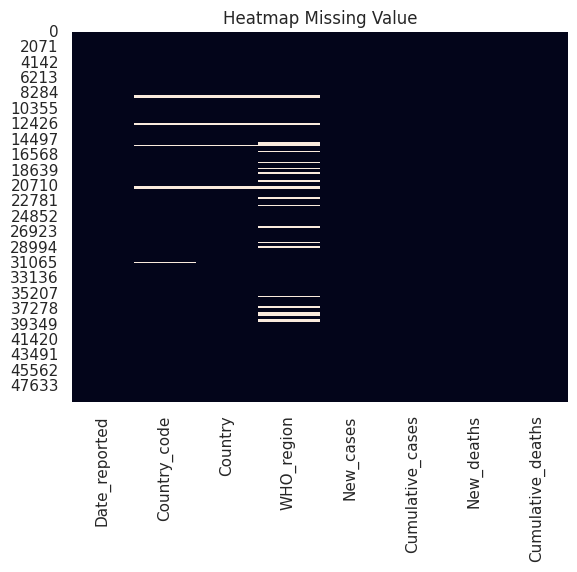

In [ ]:
# Visualisasi Missing Value dengan Hitmap
sns.heatmap(data1.isnull(), cbar=False)
plt.title('Heatmap Missing Value')
plt.show()

In [ ]:
# Karena terdapat banyak Missing Value, jadi langsung dihapus
data1.dropna(inplace=True)

In [ ]:
# Mengecek kembali Missing Value
data1.isnull().sum()

Date_reported        0
Country_code         0
Country              0
WHO_region           0
New_cases            0
Cumulative_cases     0
New_deaths           0
Cumulative_deaths    0
dtype: int64

### Mengecek Noise dan Outlier

#### Noise

In [ ]:
# Mengampilkan statistik dari data1
data1.describe()

# Dapat terlihat bahwa terdapat data yang mines pada variable 'New_cases' dan 'New_deaths'
# Maka kita akan menghapusnya

,New_cases,Cumulative_cases,New_deaths,Cumulative_deaths
count,4.450500e+04,4.450500e+04,44505.000000,4.450500e+04
mean,1.733189e+04,1.734181e+06,156.842872,2.060065e+04
std,2.536619e+05,7.417613e+06,920.235212,8.131126e+04
min,-6.507900e+04,0.000000e+00,-3432.000000,0.000000e+00
25%,1.000000e+00,5.214000e+03,0.000000,3.900000e+01
50%,1.400000e+02,5.361800e+04,1.000000,7.040000e+02
75%,2.610000e+03,5.789660e+05,27.000000,7.680000e+03
max,4.047548e+07,1.034368e+08,47687.000000,1.144877e+06


In [ ]:
# Menghapus data yang mines pada 'New_cases' dan 'New_deaths'
data1.drop(data1[data1['New_cases']<0].index, inplace=True)
data1.drop(data1[data1['New_deaths']<0].index,inplace=True)

In [ ]:
# Cek kembali
data1.describe()

,New_cases,Cumulative_cases,New_deaths,Cumulative_deaths
count,4.447800e+04,4.447800e+04,44478.000000,4.447800e+04
mean,1.734282e+04,1.734585e+06,156.933428,2.060749e+04
std,2.537383e+05,7.419594e+06,920.152464,8.133426e+04
min,0.000000e+00,0.000000e+00,0.000000,0.000000e+00
25%,1.000000e+00,5.214250e+03,0.000000,3.900000e+01
50%,1.400000e+02,5.361350e+04,1.000000,7.040000e+02
75%,2.612000e+03,5.789268e+05,27.000000,7.675750e+03
max,4.047548e+07,1.034368e+08,47687.000000,1.144877e+06


#### Outlier

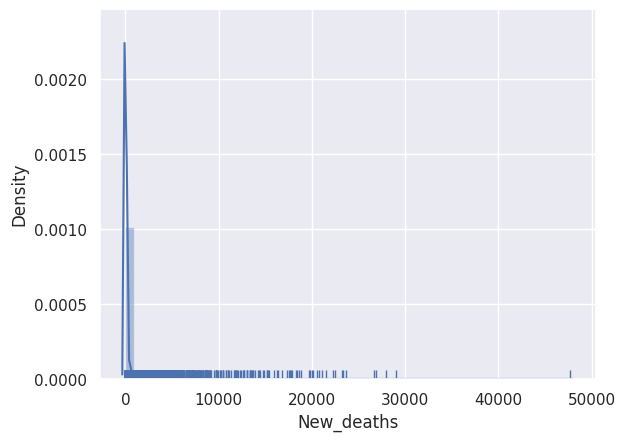

In [ ]:
plt.style.use('bmh'); sns.set() #style visualisasi

p = sns.distplot(data1['New_deaths'], kde=True, rug=True)
#Dari plot nampak adanya outlier dengan cukup jelas.

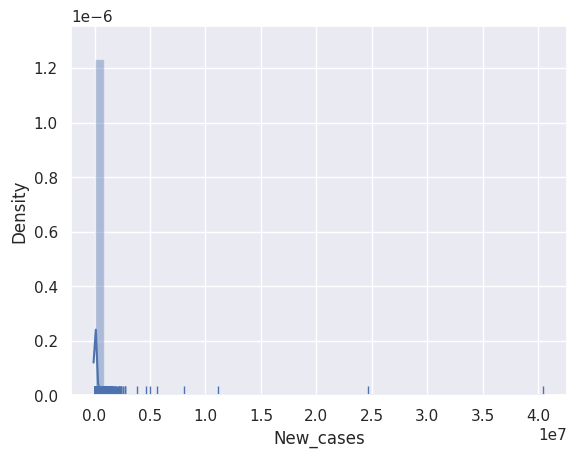

In [ ]:
plt.style.use('bmh'); sns.set() #style visualisasi

p = sns.distplot(data1['New_cases'], kde=True, rug=True)
#Dari plot nampak adanya outlier dengan cukup jelas.

## Data 2 (vaccination-data.csv)

In [ ]:
# Menginput data
data2 = pd.read_csv(data2, sep=";")
data2

,COUNTRY,ISO3,WHO_REGION,DATA_SOURCE,DATE_UPDATED,TOTAL_VACCINATIONS,PERSONS_VACCINATED_1PLUS_DOSE,TOTAL_VACCINATIONS_PER100,PERSONS_VACCINATED_1PLUS_DOSE_PER100,PERSONS_LAST_DOSE,PERSONS_LAST_DOSE_PER100,VACCINES_USED,FIRST_VACCINE_DATE,NUMBER_VACCINES_TYPES_USED,PERSONS_BOOSTER_ADD_DOSE,PERSONS_BOOSTER_ADD_DOSE_PER100,Unnamed: 16
0,Bhutan,BTN,SEARO,REPORTING,30/10/2022,2011426,699116.0,261.0,91.0,677669.0,88.0,NaN,27/03/2021,NaN,634641.0,82.0,NaN
1,Namibia,NAM,AFRO,REPORTING,12/11/2023,1005937,629767.0,40.0,25.0,550978.0,22.0,NaN,19/03/2021,NaN,298560.0,12.0,NaN
2,Iran (Islamic Republic of),IRN,EMRO,REPORTING,26/11/2023,1.55E+08,65200000.0,185.0,78.0,58600000.0,70.0,NaN,09/02/2021,NaN,31400000.0,37.0,NaN
3,Kenya,KEN,AFRO,REPORTING,02/04/2023,2.38E+07,14500000.0,44.0,27.0,11100000.0,21.0,NaN,05/03/2021,NaN,2000636.0,4.0,NaN
4,Greenland,GRL,EURO,REPORTING,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
205,Guinea-Bissau,GNB,AFRO,REPORTING,15/10/2023,920752,747057.0,47.0,38.0,547637.0,28.0,NaN,02/04/2021,NaN,76359.0,4.0,NaN
206,Liechtenstein,LIE,NaN,REPORTING,NaN,71104,26681.0,NaN,NaN,26346.0,NaN,NaN,NaN,NaN,18310.0,NaN,NaN
207,Côte d'Ivoire,CIV,AFRO,REPORTING,19/02/2023,2.53E+07,13600000.0,96.0,51.0,12200000.0,46.0,NaN,01/03/2021,NaN,3138712.0,12.0,NaN
208,Equatorial Guinea,GNQ,AFRO,REPORTING,24/07/2022,488738,270109.0,35.0,19.0,214032.0,15.0,NaN,12/02/2021,NaN,4597.0,NaN,NaN


### Mengecek Bentuk, Info, dan Tipe Data

In [ ]:
info2 = data2.info()
N, P = data2.shape

print('Baris = ', N, ', Kolom/jumlah variabel = ', P)
print('Tipe variable dari data1 = ', type(data2))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 17 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   COUNTRY                               210 non-null    object 
 1   ISO3                                  210 non-null    object 
 2   WHO_REGION                            207 non-null    object 
 3   DATA_SOURCE                           209 non-null    object 
 4   DATE_UPDATED                          206 non-null    object 
 5   TOTAL_VACCINATIONS                    204 non-null    object 
 6   PERSONS_VACCINATED_1PLUS_DOSE         204 non-null    float64
 7   TOTAL_VACCINATIONS_PER100             202 non-null    float64
 8   PERSONS_VACCINATED_1PLUS_DOSE_PER100  202 non-null    float64
 9   PERSONS_LAST_DOSE                     204 non-null    float64
 10  PERSONS_LAST_DOSE_PER100              202 non-null    float64
 11  VACCINES_USED      

### Menghapus Variable yang Tidak Diperlukan

In [ ]:
data2.drop(["DATA_SOURCE","VACCINES_USED","NUMBER_VACCINES_TYPES_USED", "TOTAL_VACCINATIONS_PER100", "Unnamed: 16"], axis=1, inplace = True)

In [ ]:
data2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 12 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   COUNTRY                               210 non-null    object 
 1   ISO3                                  210 non-null    object 
 2   WHO_REGION                            207 non-null    object 
 3   DATE_UPDATED                          206 non-null    object 
 4   TOTAL_VACCINATIONS                    204 non-null    object 
 5   PERSONS_VACCINATED_1PLUS_DOSE         204 non-null    float64
 6   PERSONS_VACCINATED_1PLUS_DOSE_PER100  202 non-null    float64
 7   PERSONS_LAST_DOSE                     204 non-null    float64
 8   PERSONS_LAST_DOSE_PER100              202 non-null    float64
 9   FIRST_VACCINE_DATE                    195 non-null    object 
 10  PERSONS_BOOSTER_ADD_DOSE              189 non-null    float64
 11  PERSONS_BOOSTER_ADD

### Menghapus Duplikasi Data

In [ ]:
# Mengecek duplikasi data berdasarkan baris dan kolom
dup2 = data2.duplicated().sum()
dup2_trans = data2.transpose().duplicated().sum()

print('Duplikasi berdasarkan baris = ', dup2)
print('Duplikasi berdasarkan kolom = ', dup2_trans)

Duplikasi berdasarkan baris =  0
Duplikasi berdasarkan kolom =  0


Pada pengecekan di atas, tidak ada data yang terduplikasi, namun pada saat kami cek pada kolom 'COUNTRY' ternyata terdapat duplikasi

In [ ]:
data2.duplicated(['COUNTRY']).sum()

2

In [ ]:
# Menghapus duplikasi pada kolom "COUNTRY"
data2.drop_duplicates(subset = ["COUNTRY"], inplace = True)

In [ ]:
# Cek kembali
data2.duplicated(['COUNTRY']).sum()

0

### Mengubah Tipe Variable Data

In [ ]:
data2['TOTAL_VACCINATIONS'] = data2['TOTAL_VACCINATIONS'].astype('float')
data2['WHO_REGION'] = data2['WHO_REGION'].astype('category')
data2['DATE_UPDATED'] = pd.to_datetime(data2['DATE_UPDATED'])
data2['FIRST_VACCINE_DATE'] = pd.to_datetime(data2['FIRST_VACCINE_DATE'])
data2.dtypes

ValueError: ignored

Di sini terdapat error karena saat kami cek pada data2 di excel, terdapat bagian dari kolom "DATE_UPDATED" yang bergeser ke kolom "TOTAL_VACCINATIONS". Sehingga ini terdeteksi sebagai noise. Jadi sebelum mengubah tipe data, kami hapus dulu baris yang bermasalah tersebut

In [ ]:
# Menghapus baris dalam data data2 yang memiliki nilai 'TOTAL_VACCINATIONS' sama dengan '18/10/2022'
data2 = data2[data2['TOTAL_VACCINATIONS'] != '18/10/2022']

In [ ]:
# Menghapus baris dalam data data2 yang memiliki nilai 'DATE_UPDATED' sama dengan 'REPORTING'
data2 = data2[data2['DATE_UPDATED'] != 'REPORTING']

In [ ]:
data2['TOTAL_VACCINATIONS'] = data2['TOTAL_VACCINATIONS'].astype('float')
data2['DATE_UPDATED'] = pd.to_datetime(data2['DATE_UPDATED'])
data2['FIRST_VACCINE_DATE'] = pd.to_datetime(data2['FIRST_VACCINE_DATE'])
data2.dtypes

COUNTRY                                         object
ISO3                                            object
WHO_REGION                                      object
DATE_UPDATED                            datetime64[ns]
TOTAL_VACCINATIONS                             float64
PERSONS_VACCINATED_1PLUS_DOSE                  float64
PERSONS_VACCINATED_1PLUS_DOSE_PER100           float64
PERSONS_LAST_DOSE                              float64
PERSONS_LAST_DOSE_PER100                       float64
FIRST_VACCINE_DATE                      datetime64[ns]
PERSONS_BOOSTER_ADD_DOSE                       float64
PERSONS_BOOSTER_ADD_DOSE_PER100                float64
dtype: object

### Menghapus Missing Value

In [ ]:
# Mengecek Missing Value
data2.isnull().sum()

COUNTRY                                  0
ISO3                                     0
WHO_REGION                               3
DATE_UPDATED                             4
TOTAL_VACCINATIONS                       3
PERSONS_VACCINATED_1PLUS_DOSE            3
PERSONS_VACCINATED_1PLUS_DOSE_PER100     5
PERSONS_LAST_DOSE                        3
PERSONS_LAST_DOSE_PER100                 5
FIRST_VACCINE_DATE                      11
PERSONS_BOOSTER_ADD_DOSE                17
PERSONS_BOOSTER_ADD_DOSE_PER100         28
dtype: int64

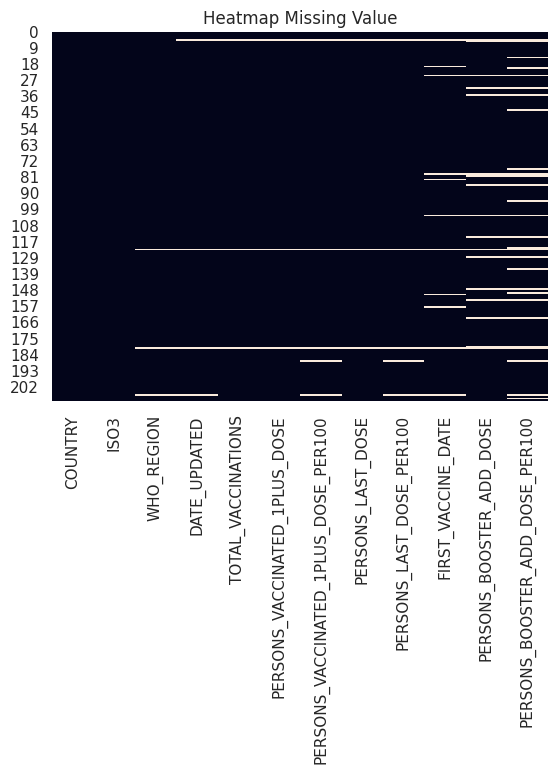

In [ ]:
# Visualisasi Missing Value dengan Hitmap
sns.heatmap(data2.isnull(), cbar=False)
plt.title('Heatmap Missing Value')
plt.show()

In [ ]:
# Karena terdapat banyak Missing Value, jadi langsung dihapus
data2.dropna(inplace=True)

In [ ]:
# Mengecek kembali Missing Value
data2.isnull().sum()

COUNTRY                                 0
ISO3                                    0
WHO_REGION                              0
DATE_UPDATED                            0
TOTAL_VACCINATIONS                      0
PERSONS_VACCINATED_1PLUS_DOSE           0
PERSONS_VACCINATED_1PLUS_DOSE_PER100    0
PERSONS_LAST_DOSE                       0
PERSONS_LAST_DOSE_PER100                0
FIRST_VACCINE_DATE                      0
PERSONS_BOOSTER_ADD_DOSE                0
PERSONS_BOOSTER_ADD_DOSE_PER100         0
dtype: int64

### Menghapus Noise dan Outlier

#### Noise

In [ ]:
data2.describe()

,TOTAL_VACCINATIONS,PERSONS_VACCINATED_1PLUS_DOSE,PERSONS_VACCINATED_1PLUS_DOSE_PER100,PERSONS_LAST_DOSE,PERSONS_LAST_DOSE_PER100,PERSONS_BOOSTER_ADD_DOSE,PERSONS_BOOSTER_ADD_DOSE_PER100
count,1.740000e+02,1.740000e+02,174.000000,1.740000e+02,174.000000,1.740000e+02,174.000000
mean,7.425530e+07,3.037376e+07,65.965517,2.796190e+07,60.770115,1.407723e+07,32.264368
std,3.240964e+08,1.301929e+08,21.588076,1.234802e+08,22.076169,6.724795e+07,23.275162
min,4.619000e+03,1.638000e+03,10.000000,1.635000e+03,9.000000,5.630000e+02,1.000000
25%,1.304310e+06,6.396328e+05,49.250000,5.412988e+05,43.250000,1.677635e+05,9.250000
50%,9.518414e+06,4.331162e+06,70.000000,4.184766e+06,64.500000,1.130274e+06,31.000000
75%,2.880000e+07,1.510000e+07,83.750000,1.310000e+07,79.000000,5.676290e+06,54.000000
max,3.520000e+09,1.320000e+09,100.000000,1.280000e+09,100.000000,8.340000e+08,83.000000


Karena data ini tidak ada yang angka yang min, maka pada variable tipe float, tidak perlu mencari noisenya. Sedangkan untuk variable tipe string, akan tetap dicek noisenya

In [ ]:
# Mengecek noise pada kolom "WHO_REGION"
data2["WHO_REGION"].value_counts()

EURO     48
AMRO     40
AFRO     33
WPRO     28
EMRO     15
SEARO    10
Name: WHO_REGION, dtype: int64

In [ ]:
# Mengecek noise pada kolom "COUNTRY"
data2["COUNTRY"].value_counts()

Bhutan                          1
Paraguay                        1
Peru                            1
Saint Lucia                     1
Netherlands (Kingdom of the)    1
                               ..
Seychelles                      1
Monaco                          1
Albania                         1
Chile                           1
Egypt                           1
Name: COUNTRY, Length: 174, dtype: int64

#### Outlier

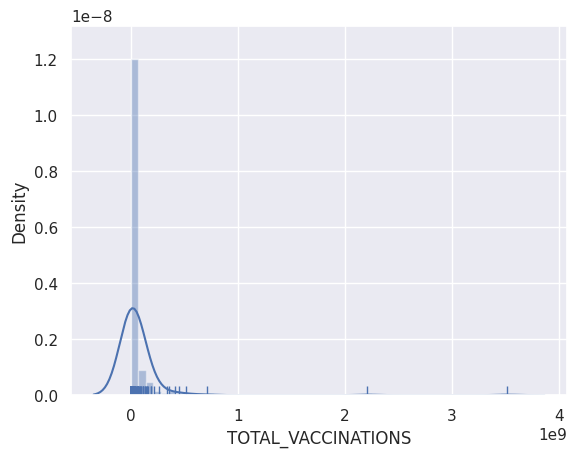

In [ ]:
# Mengecek outlier pada kolom "TOTAL_VACCINATIONS"
plt.style.use('bmh'); sns.set() #style visualisasi

p = sns.distplot(data2['TOTAL_VACCINATIONS'], kde=True, rug=True)

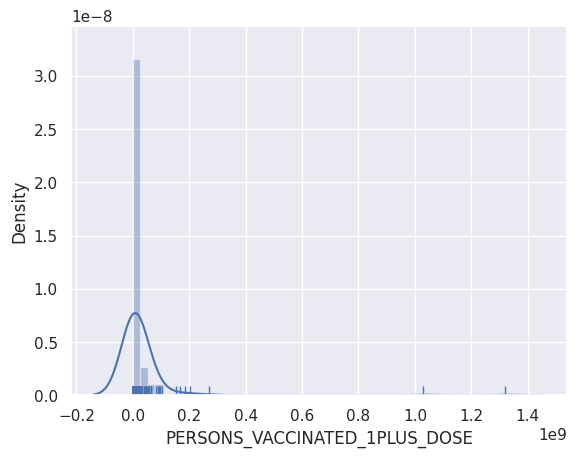

In [ ]:
# Mengecek outlier pada kolom "PERSONS_VACCINATED_1PLUS_DOSE"
plt.style.use('bmh'); sns.set() #style visualisasi

p = sns.distplot(data2['PERSONS_VACCINATED_1PLUS_DOSE'], kde=True, rug=True)

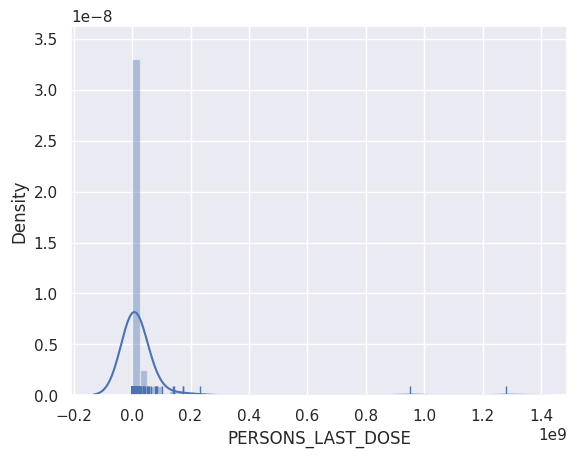

In [ ]:
# Mengecek outlier pada kolom "PERSONS_LAST_DOSE"
plt.style.use('bmh'); sns.set() #style visualisasi

p = sns.distplot(data2['PERSONS_LAST_DOSE'], kde=True, rug=True)

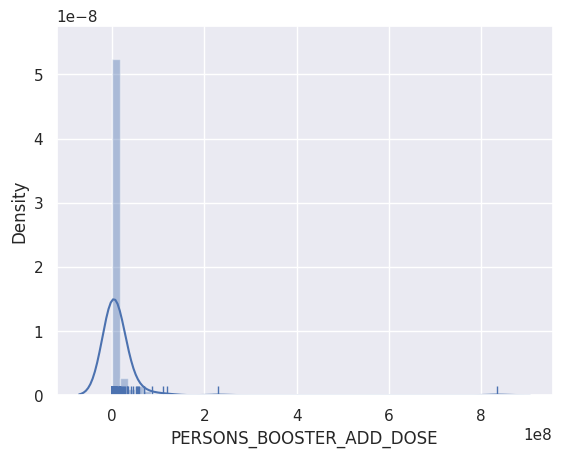

In [ ]:
# Mengecek outlier pada kolom "PERSONS_BOOSTER_ADD_DOSE"
plt.style.use('bmh'); sns.set() #style visualisasi

p = sns.distplot(data2['PERSONS_BOOSTER_ADD_DOSE'], kde=True, rug=True)

Karena data ini merupakand data realtime/kontinu, maka outlier ini tidak dihilangkan

## Menyimpan data yang sudah di preprocessing

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Menyimpan file csv data1 ke drive
data1.to_csv("/content/drive/MyDrive/Colab Notebooks/EDA/Project UAS EDA/covid_PreProcessed.csv", encoding='utf8')

In [ ]:
# Menyimpan file csv data2 ke drive
data2.to_csv("/content/drive/MyDrive/Colab Notebooks/EDA/Project UAS EDA/vaksin_PreProcessed.csv", encoding='utf8')

# **3. Data Wrangling**

In [ ]:
from google.colab import files
file_data = files.upload()

Saving covid_PreProcessed.csv to covid_PreProcessed.csv
Saving vaksin_PreProcessed.csv to vaksin_PreProcessed.csv


In [ ]:
covid = 'covid_PreProcessed.csv'
vaksin = 'vaksin_PreProcessed.csv'

In [ ]:
df_cov = pd.read_csv(covid)
df_vak = pd.read_csv(vaksin)

In [ ]:
## Menyamakan nama variabel 'country' dan 'who_region' dengan data covid
## Tujuannya agar memudahkan untuk menggabungkan data covid dan data vaksin berdasarkan variabel 'country' dan 'who_region'
df_vak.rename(columns = {'COUNTRY':'Country', 'WHO_REGION':'WHO_region'}, inplace = True )
df_vak

,Unnamed: 0,Country,ISO3,WHO_region,DATE_UPDATED,TOTAL_VACCINATIONS,PERSONS_VACCINATED_1PLUS_DOSE,PERSONS_VACCINATED_1PLUS_DOSE_PER100,PERSONS_LAST_DOSE,PERSONS_LAST_DOSE_PER100,FIRST_VACCINE_DATE,PERSONS_BOOSTER_ADD_DOSE,PERSONS_BOOSTER_ADD_DOSE_PER100
0,0,Bhutan,BTN,SEARO,2022-10-30,2011426.0,699116.0,91.0,677669.0,88.0,2021-03-27,634641.0,82.0
1,1,Namibia,NAM,AFRO,2023-12-11,1005937.0,629767.0,25.0,550978.0,22.0,2021-03-19,298560.0,12.0
2,2,Iran (Islamic Republic of),IRN,EMRO,2023-11-26,155000000.0,65200000.0,78.0,58600000.0,70.0,2021-09-02,31400000.0,37.0
3,3,Kenya,KEN,AFRO,2023-02-04,23800000.0,14500000.0,27.0,11100000.0,21.0,2021-05-03,2000636.0,4.0
4,6,Mozambique,MOZ,AFRO,2023-02-07,35000000.0,22900000.0,73.0,21300000.0,68.0,2021-08-03,2323562.0,7.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
169,203,Japan,JPN,WPRO,2023-03-10,410000000.0,105000000.0,83.0,103000000.0,82.0,2021-02-17,86600000.0,68.0
170,204,Spain,ESP,EURO,2023-03-09,113000000.0,41300000.0,87.0,37500000.0,79.0,2020-12-30,26600000.0,56.0
171,205,Guinea-Bissau,GNB,AFRO,2023-10-15,920752.0,747057.0,38.0,547637.0,28.0,2021-02-04,76359.0,4.0
172,207,Côte d'Ivoire,CIV,AFRO,2023-02-19,25300000.0,13600000.0,51.0,12200000.0,46.0,2021-01-03,3138712.0,12.0


In [ ]:
## Membuang kolom 'Unnamed: 0'
df_vak.drop(["Unnamed: 0"], axis=1, inplace=True)
df_vak

,Country,ISO3,WHO_region,DATE_UPDATED,TOTAL_VACCINATIONS,PERSONS_VACCINATED_1PLUS_DOSE,PERSONS_VACCINATED_1PLUS_DOSE_PER100,PERSONS_LAST_DOSE,PERSONS_LAST_DOSE_PER100,FIRST_VACCINE_DATE,PERSONS_BOOSTER_ADD_DOSE,PERSONS_BOOSTER_ADD_DOSE_PER100
0,Bhutan,BTN,SEARO,2022-10-30,2011426.0,699116.0,91.0,677669.0,88.0,2021-03-27,634641.0,82.0
1,Namibia,NAM,AFRO,2023-12-11,1005937.0,629767.0,25.0,550978.0,22.0,2021-03-19,298560.0,12.0
2,Iran (Islamic Republic of),IRN,EMRO,2023-11-26,155000000.0,65200000.0,78.0,58600000.0,70.0,2021-09-02,31400000.0,37.0
3,Kenya,KEN,AFRO,2023-02-04,23800000.0,14500000.0,27.0,11100000.0,21.0,2021-05-03,2000636.0,4.0
4,Mozambique,MOZ,AFRO,2023-02-07,35000000.0,22900000.0,73.0,21300000.0,68.0,2021-08-03,2323562.0,7.0
...,...,...,...,...,...,...,...,...,...,...,...,...
169,Japan,JPN,WPRO,2023-03-10,410000000.0,105000000.0,83.0,103000000.0,82.0,2021-02-17,86600000.0,68.0
170,Spain,ESP,EURO,2023-03-09,113000000.0,41300000.0,87.0,37500000.0,79.0,2020-12-30,26600000.0,56.0
171,Guinea-Bissau,GNB,AFRO,2023-10-15,920752.0,747057.0,38.0,547637.0,28.0,2021-02-04,76359.0,4.0
172,Côte d'Ivoire,CIV,AFRO,2023-02-19,25300000.0,13600000.0,51.0,12200000.0,46.0,2021-01-03,3138712.0,12.0


In [ ]:
## Mencari total new cases di setiap negara dan mencari total new deaths di setiap negara dari data covid
## Dengan menggunakan groupby dari variabel country
cases_country = df_cov['New_cases'].groupby(df_cov['Country']).sum()
cases_country

Country
Afghanistan                                                 229686
Albania                                                     334090
Algeria                                                     272010
American Samoa                                                8359
Andorra                                                      48015
                                                             ...  
Wallis and Futuna                                             3550
Yemen                                                        11945
Zambia                                                      349304
Zimbabwe                                                    265976
occupied Palestinian territory, including east Jerusalem    703228
Name: New_cases, Length: 215, dtype: int64

In [ ]:
deaths_country = df_cov['New_deaths'].groupby(df_cov['Country']).sum()
deaths_country

Country
Afghanistan                                                 7966
Albania                                                     3604
Algeria                                                     6881
American Samoa                                                34
Andorra                                                      159
                                                            ... 
Wallis and Futuna                                              8
Yemen                                                       2159
Zambia                                                      4069
Zimbabwe                                                    5729
occupied Palestinian territory, including east Jerusalem    5708
Name: New_deaths, Length: 215, dtype: int64

In [ ]:
## Mencari total vaksin di setiap negara dari data vaksin
## Dengan menggunakan groupby dari variabel country
vaccine_country = df_vak['TOTAL_VACCINATIONS'].groupby(df_vak['Country']).sum()
vaccine_country

Country
Afghanistan                            22600000.0
Albania                                 3088966.0
Algeria                                15300000.0
Andorra                                  157072.0
Angola                                 27700000.0
                                         ...     
Venezuela (Bolivarian Republic of)     37900000.0
Viet Nam                              266000000.0
Wallis and Futuna                         17303.0
Zambia                                 13600000.0
Zimbabwe                               13900000.0
Name: TOTAL_VACCINATIONS, Length: 174, dtype: float64

In [ ]:
## mengubah total new cases, total new deaths, total vaksin di setiap negara menjadi data frame
df_cases_country = pd.DataFrame(cases_country)
df_deaths_country = pd.DataFrame(deaths_country)
df_vaccine_country = pd.DataFrame(vaccine_country)

In [ ]:
df_cases_country

,New_cases
Country,
Afghanistan,229686
Albania,334090
Algeria,272010
American Samoa,8359
Andorra,48015
...,...
Wallis and Futuna,3550
Yemen,11945
Zambia,349304


In [ ]:
df_deaths_country

,New_deaths
Country,
Afghanistan,7966
Albania,3604
Algeria,6881
American Samoa,34
Andorra,159
...,...
Wallis and Futuna,8
Yemen,2159
Zambia,4069


In [ ]:
df_vaccine_country

,TOTAL_VACCINATIONS
Country,
Afghanistan,22600000.0
Albania,3088966.0
Algeria,15300000.0
Andorra,157072.0
Angola,27700000.0
...,...
Venezuela (Bolivarian Republic of),37900000.0
Viet Nam,266000000.0
Wallis and Futuna,17303.0


In [ ]:
## Menggabungkan df_cases_country dan df_cases_country berdasarkan 'Country'
df_merge_cov = pd.merge( df_cases_country, df_deaths_country, on = 'Country')
df_merge_cov

,New_cases,New_deaths
Country,,
Afghanistan,229686,7966
Albania,334090,3604
Algeria,272010,6881
American Samoa,8359,34
Andorra,48015,159
...,...,...
Wallis and Futuna,3550,8
Yemen,11945,2159
Zambia,349304,4069


In [ ]:
## Menambah kolom baru 'Tingkat_Kematian' untuk mencari tingkat kematian dari covid-19 di setiap negara
## 'Tingkat_Kematian' didapatkan dari tiap baris 'New_deaths' dibagi dengan tiap baris 'New_cases'
df_merge_cov['Tingkat_Kematian'] = df_merge_cov.apply(lambda row: row['New_deaths'] / row['New_cases'], axis=1)
df_merge_cov

,New_cases,New_deaths,Tingkat_Kematian
Country,,,
Afghanistan,229686,7966,0.034682
Albania,334090,3604,0.010788
Algeria,272010,6881,0.025297
American Samoa,8359,34,0.004067
Andorra,48015,159,0.003311
...,...,...,...
Wallis and Futuna,3550,8,0.002254
Yemen,11945,2159,0.180745
Zambia,349304,4069,0.011649


In [ ]:
### Menambah kolom baru 'Mean_Person_Vac' untuk mencari rata-rata orang yang sudah divaksin di setiap negara
## 'Mean_Person_Vac' didapatkan dari tiap baris 'TOTAL_VACCINATIONS' dibagi dengan 3 karena 'TOTAL_VACCINATIONS' merupakan total vaksin tiap orang setiap orang selama tiga kali vaksin
df_vaccine_country['Mean_Person_Vac'] = df_vaccine_country.apply(lambda row: row['TOTAL_VACCINATIONS'] / 3, axis=1)
df_vaccine_country

,TOTAL_VACCINATIONS,Mean_Person_Vac
Country,,
Afghanistan,22600000.0,7.533333e+06
Albania,3088966.0,1.029655e+06
Algeria,15300000.0,5.100000e+06
Andorra,157072.0,5.235733e+04
Angola,27700000.0,9.233333e+06
...,...,...
Venezuela (Bolivarian Republic of),37900000.0,1.263333e+07
Viet Nam,266000000.0,8.866667e+07
Wallis and Futuna,17303.0,5.767667e+03


In [ ]:
## Menggabungkan data Frame dari df_merge_cov dan df_vaccine_country berdasarkan 'Country'
df_cov_vac_country = pd.merge( df_merge_cov, df_vaccine_country, on = 'Country')
df_cov_vac_country

,New_cases,New_deaths,Tingkat_Kematian,TOTAL_VACCINATIONS,Mean_Person_Vac
Country,,,,,
Afghanistan,229686,7966,0.034682,22600000.0,7.533333e+06
Albania,334090,3604,0.010788,3088966.0,1.029655e+06
Algeria,272010,6881,0.025297,15300000.0,5.100000e+06
Andorra,48015,159,0.003311,157072.0,5.235733e+04
Angola,106303,1937,0.018221,27700000.0,9.233333e+06
...,...,...,...,...,...
Venezuela (Bolivarian Republic of),552695,5856,0.010595,37900000.0,1.263333e+07
Viet Nam,11624000,43206,0.003717,266000000.0,8.866667e+07
Wallis and Futuna,3550,8,0.002254,17303.0,5.767667e+03


In [ ]:
## Mengambil beberapa kolom dari data vaksin
dosis_vaksin = df_vak[['Country','WHO_region', 'PERSONS_VACCINATED_1PLUS_DOSE_PER100', 'PERSONS_LAST_DOSE_PER100', 'PERSONS_BOOSTER_ADD_DOSE_PER100']]
dosis_vaksin

,Country,WHO_region,PERSONS_VACCINATED_1PLUS_DOSE_PER100,PERSONS_LAST_DOSE_PER100,PERSONS_BOOSTER_ADD_DOSE_PER100
0,Bhutan,SEARO,91.0,88.0,82.0
1,Namibia,AFRO,25.0,22.0,12.0
2,Iran (Islamic Republic of),EMRO,78.0,70.0,37.0
3,Kenya,AFRO,27.0,21.0,4.0
4,Mozambique,AFRO,73.0,68.0,7.0
...,...,...,...,...,...
169,Japan,WPRO,83.0,82.0,68.0
170,Spain,EURO,87.0,79.0,56.0
171,Guinea-Bissau,AFRO,38.0,28.0,4.0
172,Côte d'Ivoire,AFRO,51.0,46.0,12.0


In [ ]:
### Menambah kolom baru 'Mean_dosis_vaksin' pada dosis_vaksin untuk mencari rata-rata dosis vaksin yang diberikan di setiap negara
## 'Mean_dosis_vaksin' didapatkan dari tiap baris jumlah baris dari 'PERSONS_VACCINATED_1PLUS_DOSE_PER100', 'PERSONS_LAST_DOSE_PER100', 'PERSONS_BOOSTER_ADD_DOSE_PER100' dibagi dengan 3
dosis_vaksin['Mean_dosis_vaksin'] = dosis_vaksin.apply(lambda row: (row['PERSONS_VACCINATED_1PLUS_DOSE_PER100'] + row['PERSONS_LAST_DOSE_PER100']+ row['PERSONS_BOOSTER_ADD_DOSE_PER100'])/3, axis=1)
dosis_vaksin

,Country,WHO_region,PERSONS_VACCINATED_1PLUS_DOSE_PER100,PERSONS_LAST_DOSE_PER100,PERSONS_BOOSTER_ADD_DOSE_PER100,Mean_dosis_vaksin
0,Bhutan,SEARO,91.0,88.0,82.0,87.000000
1,Namibia,AFRO,25.0,22.0,12.0,19.666667
2,Iran (Islamic Republic of),EMRO,78.0,70.0,37.0,61.666667
3,Kenya,AFRO,27.0,21.0,4.0,17.333333
4,Mozambique,AFRO,73.0,68.0,7.0,49.333333
...,...,...,...,...,...,...
169,Japan,WPRO,83.0,82.0,68.0,77.666667
170,Spain,EURO,87.0,79.0,56.0,74.000000
171,Guinea-Bissau,AFRO,38.0,28.0,4.0,23.333333
172,Côte d'Ivoire,AFRO,51.0,46.0,12.0,36.333333


In [ ]:
## Menggabungkan dataFrame df_cov_vac_country dosis_vaksin_negara berdasrkan 'Country'
df_vak_cov = pd.merge( df_cov_vac_country, dosis_vaksin, on = 'Country')
df_vak_cov

,Country,New_cases,New_deaths,Tingkat_Kematian,TOTAL_VACCINATIONS,Mean_Person_Vac,WHO_region,PERSONS_VACCINATED_1PLUS_DOSE_PER100,PERSONS_LAST_DOSE_PER100,PERSONS_BOOSTER_ADD_DOSE_PER100,Mean_dosis_vaksin
0,Afghanistan,229686,7966,0.034682,22600000.0,7.533333e+06,EMRO,49.0,47.0,7.0,34.333333
1,Albania,334090,3604,0.010788,3088966.0,1.029655e+06,EURO,47.0,44.0,14.0,35.000000
2,Algeria,272010,6881,0.025297,15300000.0,5.100000e+06,AFRO,18.0,15.0,1.0,11.333333
3,Andorra,48015,159,0.003311,157072.0,5.235733e+04,EURO,75.0,69.0,56.0,66.666667
4,Angola,106303,1937,0.018221,27700000.0,9.233333e+06,AFRO,50.0,29.0,9.0,29.333333
...,...,...,...,...,...,...,...,...,...,...,...
168,Venezuela (Bolivarian Republic of),552695,5856,0.010595,37900000.0,1.263333e+07,AMRO,78.0,50.0,2.0,43.333333
169,Viet Nam,11624000,43206,0.003717,266000000.0,8.866667e+07,WPRO,93.0,88.0,60.0,80.333333
170,Wallis and Futuna,3550,8,0.002254,17303.0,5.767667e+03,WPRO,64.0,60.0,30.0,51.333333
171,Zambia,349304,4069,0.011649,13600000.0,4.533333e+06,AFRO,64.0,50.0,8.0,40.666667


In [ ]:
## Mencari jumlah per value dari kolom 'WHO_region'
WHO_region_counts=df_vak_cov['WHO_region'].value_counts ()
WHO_region_counts

EURO     48
AMRO     40
AFRO     32
WPRO     28
EMRO     15
SEARO    10
Name: WHO_region, dtype: int64

In [ ]:
## Mencari total kematian di setiap wilayah WHO dari data df_dosis_negara
## Dengan menggunakan groupby dari variabel 'WHO_region'
region_kematian=df_vak_cov['New_deaths'].groupby([df_vak_cov['WHO_region']]).sum()
region_kematian

WHO_region
AFRO      164459
AMRO     2956608
EMRO      336221
EURO     1487062
SEARO     808175
WPRO      417559
Name: New_deaths, dtype: int64

In [ ]:
df_WHO_region_counts = pd.DataFrame(WHO_region_counts)
df_region_kematian = pd.DataFrame(region_kematian)

In [ ]:
df_region_kematian['means_deaths'] = df_region_kematian['New_deaths']/ WHO_region_counts
df_region_kematian

,New_deaths,means_deaths
WHO_region,,
AFRO,164459,5139.343750
AMRO,2956608,73915.200000
EMRO,336221,22414.733333
EURO,1487062,30980.458333
SEARO,808175,80817.500000
WPRO,417559,14912.821429


In [ ]:
df_region_kematian.drop(["New_deaths"], axis=1, inplace=True)
df_region_kematian

,means_deaths
WHO_region,
AFRO,5139.343750
AMRO,73915.200000
EMRO,22414.733333
EURO,30980.458333
SEARO,80817.500000
WPRO,14912.821429


In [ ]:
region_vaksin=df_vak_cov['Mean_Person_Vac'].groupby([df_vak_cov['WHO_region']]).sum()
df_region_vaksin = pd.DataFrame(region_vaksin)

In [ ]:
df_region_vaksin['means_vac'] = df_region_vaksin['Mean_Person_Vac']/ WHO_region_counts
df_region_vaksin

,Mean_Person_Vac,means_vac
WHO_region,,
AFRO,1.845395e+08,5.766860e+06
AMRO,7.128597e+08,1.782149e+07
EMRO,2.831668e+08,1.887778e+07
EURO,4.167704e+08,8.682717e+06
SEARO,1.121397e+09,1.121397e+08
WPRO,1.587738e+09,5.670494e+07


In [ ]:
df_region_vaksin.drop(["Mean_Person_Vac"], axis=1, inplace=True)
df_region_vaksin

,means_vac
WHO_region,
AFRO,5.766860e+06
AMRO,1.782149e+07
EMRO,1.887778e+07
EURO,8.682717e+06
SEARO,1.121397e+08
WPRO,5.670494e+07


In [ ]:
region_tingkat_dosis = df_vak_cov['Mean_dosis_vaksin'].groupby([df_vak_cov['WHO_region']]).sum()
df_region_dosis = pd.DataFrame(region_tingkat_dosis)

In [ ]:
df_region_dosis['means_dosis'] = df_region_dosis['Mean_dosis_vaksin']/ WHO_region_counts
df_region_dosis

,Mean_dosis_vaksin,means_dosis
WHO_region,,
AFRO,1062.666667,33.208333
AMRO,2123.666667,53.091667
EMRO,645.333333,43.022222
EURO,2746.000000,57.208333
SEARO,638.333333,63.833333
WPRO,1986.333333,70.940476


In [ ]:
df_region_dosis.drop(["Mean_dosis_vaksin"], axis=1, inplace=True)
df_region_dosis

,means_dosis
WHO_region,
AFRO,33.208333
AMRO,53.091667
EMRO,43.022222
EURO,57.208333
SEARO,63.833333
WPRO,70.940476


In [ ]:
dosis_vac_benua = pd.merge(df_region_vaksin, df_region_dosis, on = 'WHO_region')
dosis_vac_benua

,means_vac,means_dosis
WHO_region,,
AFRO,5.766860e+06,33.208333
AMRO,1.782149e+07,53.091667
EMRO,1.887778e+07,43.022222
EURO,8.682717e+06,57.208333
SEARO,1.121397e+08,63.833333
WPRO,5.670494e+07,70.940476


In [ ]:
region_cases=df_vak_cov['New_cases'].groupby([df_vak_cov['WHO_region']]).sum()
df_region_cases = pd.DataFrame(region_cases)

In [ ]:
df_region_cases['means_cases'] = df_region_cases['New_cases']/ WHO_region_counts
df_region_cases

,New_cases,means_cases
WHO_region,,
AFRO,8377919,2.618100e+05
AMRO,190081351,4.752034e+06
EMRO,21010707,1.400714e+06
EURO,208959850,4.353330e+06
SEARO,61219679,6.121968e+06
WPRO,207646212,7.415936e+06


In [ ]:
df_region_cases.drop(["New_cases"], axis=1, inplace=True)
df_region_cases

,means_cases
WHO_region,
AFRO,2.618100e+05
AMRO,4.752034e+06
EMRO,1.400714e+06
EURO,4.353330e+06
SEARO,6.121968e+06
WPRO,7.415936e+06


In [ ]:
## mencari tingkat kematian
df_region_kematian['deaths_'] = df_region_kematian['means_deaths']/ df_region_cases['means_cases']
df_region_kematian

,means_deaths,deaths_
WHO_region,,
AFRO,5139.343750,0.019630
AMRO,73915.200000,0.015554
EMRO,22414.733333,0.016002
EURO,30980.458333,0.007116
SEARO,80817.500000,0.013201
WPRO,14912.821429,0.002011


In [ ]:
df_region_kematian.drop(["means_deaths"], axis=1, inplace=True)
df_region_kematian

,deaths_
WHO_region,
AFRO,0.019630
AMRO,0.015554
EMRO,0.016002
EURO,0.007116
SEARO,0.013201
WPRO,0.002011


In [ ]:
cases_vac_ = pd.merge( df_region_cases, df_region_vaksin, on = 'WHO_region')
cases_vac_

,means_cases,means_vac
WHO_region,,
AFRO,2.618100e+05,5.766860e+06
AMRO,4.752034e+06,1.782149e+07
EMRO,1.400714e+06,1.887778e+07
EURO,4.353330e+06,8.682717e+06
SEARO,6.121968e+06,1.121397e+08
WPRO,7.415936e+06,5.670494e+07


# **4. Data Visualisasi**

## 1. Penyebaran Kasus COVID-19 di Seluruh Dunia

In [ ]:
df_cov['Date_reported'] = pd.to_datetime(df_cov['Date_reported'])

In [ ]:
# Inisialisasi log_scale_vals
log_scale_vals = list(range(0,50,2))
scale_vals = [2**val for val in log_scale_vals]

Cumulative_cases_COVID = df_cov[['Date_reported', 'Country', 'Cumulative_cases']].sort_values('Date_reported')
Cumulative_cases_COVID = Cumulative_cases_COVID[Cumulative_cases_COVID.Cumulative_cases > 0]
Cumulative_cases_COVID['log2(Cumulative_cases)'] = np.log2(Cumulative_cases_COVID['Cumulative_cases'])
Cumulative_cases_COVID['Date_reported'] = Cumulative_cases_COVID['Date_reported'].dt.strftime('%Y-%m-%d')

fig = px.choropleth(Cumulative_cases_COVID, locations="Country", locationmode='country names',
                    color="log2(Cumulative_cases)", hover_name="Country", hover_data=['Cumulative_cases'],
                    projection="natural earth", animation_frame="Date_reported",
                    title='<b>Kuantitas Penyebaran Kasus COVID-19 di Seluruh Dunia Sepanjang Waktu</b>',
                    color_continuous_scale="reds",
                   )

fig.update_layout(coloraxis={"colorbar": {"title":"<b>Total Kasus</b><br>",
                                          "titleside":"top",
                                          "tickmode":"array",
                                          "tickvals":log_scale_vals,
                                          "ticktext":scale_vals}
                            }
                 )

fig.layout.updatemenus[0].buttons[0].args[1]['frame']['duration'] = 1000
fig.layout.updatemenus[0].buttons[0].args[1]['transition']['duration'] = 500

fig.show()

## 2. perkembangan tren harian dari jumlah kasus COVID-19

In [ ]:
# Mengubah Date_reported menjadi indeks
df_cov = pd.read_csv(covid, parse_dates=True, index_col = "Date_reported", error_bad_lines=False, low_memory = False)
df_cov.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 44478 entries, 2020-05-01 to 2023-12-17
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Unnamed: 0         44478 non-null  int64 
 1   Country_code       44478 non-null  object
 2   Country            44478 non-null  object
 3   WHO_region         44478 non-null  object
 4   New_cases          44478 non-null  int64 
 5   Cumulative_cases   44478 non-null  int64 
 6   New_deaths         44478 non-null  int64 
 7   Cumulative_deaths  44478 non-null  int64 
dtypes: int64(5), object(3)
memory usage: 3.1+ MB


In [ ]:
df_cov.drop(['Unnamed: 0'], axis = 1, inplace = True)
df_cov.head()

,Country_code,Country,WHO_region,New_cases,Cumulative_cases,New_deaths,Cumulative_deaths
Date_reported,,,,,,,
2020-05-01,AF,Afghanistan,EMRO,0,0,0,0
2020-12-01,AF,Afghanistan,EMRO,0,0,0,0
2020-01-19,AF,Afghanistan,EMRO,0,0,0,0
2020-01-26,AF,Afghanistan,EMRO,0,0,0,0
2020-02-02,AF,Afghanistan,EMRO,0,0,0,0


<Axes: xlabel='Date_reported', ylabel='New_cases'>

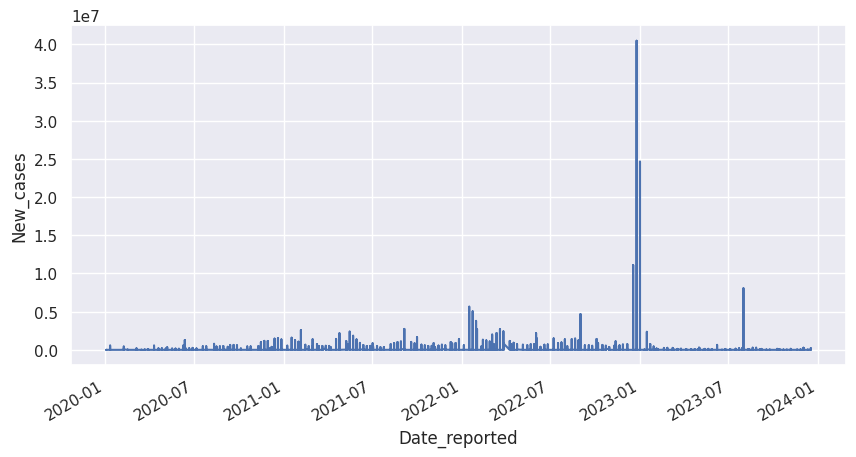

In [ ]:
df_cov['New_cases'].plot(ylabel = 'New_cases', figsize = (10,5))

Di sini dapat terlihat bahwa dari tahun 2021 awal sampai tahun 2022 akhir, semakin banyak kasus terbaru. Sampai puncaknya pada 2023 Januari. Setelah itu kasus mulai menurun

 - Menambahkan informasi hari

In [ ]:
hari_ = {0:"Senin", 1:"Selasa", 2:"Rabu", 3:"Kamis", 4:"Jumat", 5:"Sabtu", 6:"Minggu"}

df_cov['weekdays'] = ['']*df_cov.shape[0]
for i,d in df_cov.iterrows():
    df_cov.loc[i,'weekdays'] =  hari_[i.weekday()]

df_cov.head()

,Country_code,Country,WHO_region,New_cases,Cumulative_cases,New_deaths,Cumulative_deaths,weekdays
Date_reported,,,,,,,,
2020-05-01,AF,Afghanistan,EMRO,0,0,0,0,Jumat
2020-12-01,AF,Afghanistan,EMRO,0,0,0,0,Selasa
2020-01-19,AF,Afghanistan,EMRO,0,0,0,0,Minggu
2020-01-26,AF,Afghanistan,EMRO,0,0,0,0,Minggu
2020-02-02,AF,Afghanistan,EMRO,0,0,0,0,Minggu


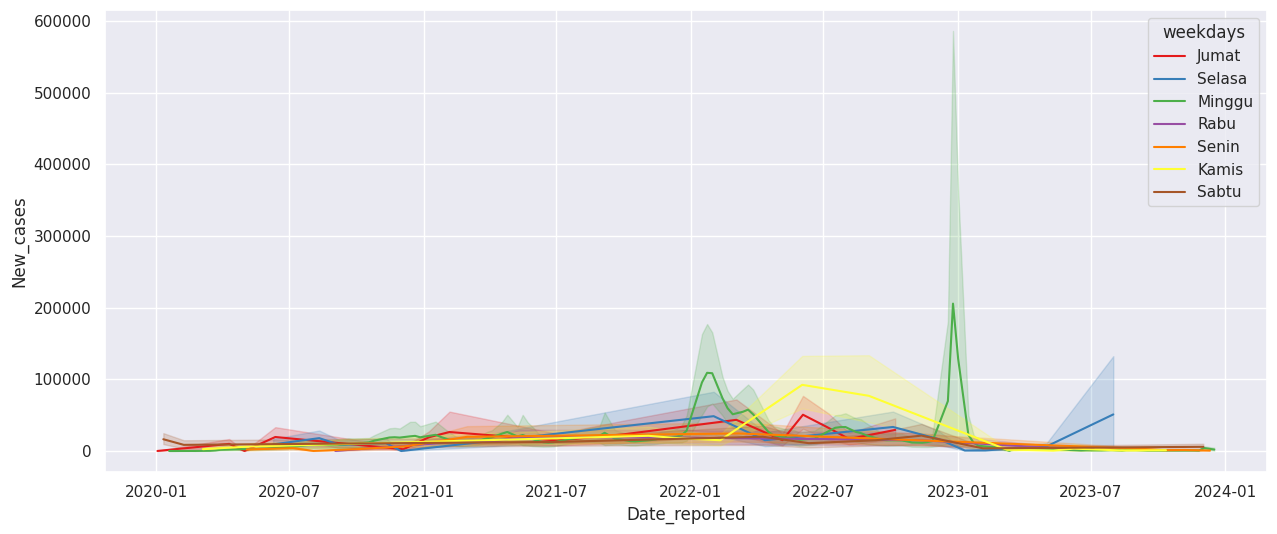

In [ ]:
plt.figure(figsize=(15,6))
sns.lineplot(x='Date_reported', y='New_cases', data=df_cov, hue='weekdays', palette='Set1')
plt.show()

Dapat terlihat bahwa kasus terbaru banyak terjadi pada hari Minggu. Karena cenderung terjadinya peningkatan mobilitas dan kontak sosial. Sehingga ini dapat meningkatkan risiko penularan virus, yang kemudian dapat tercermin dalam peningkatan kasus beberapa hari setelahnya.

**Visualisasi Data dari Data Wrangling**

## 3. Pengaruh Vaksin terhadap kasus dan kematian Covid-19 di tiap negara

In [ ]:
import matplotlib.pyplot as plt

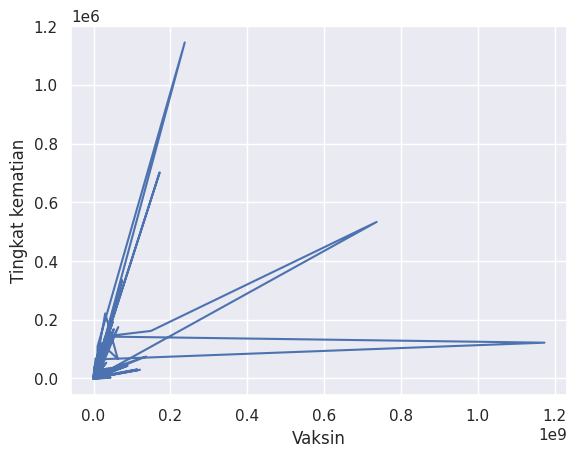

In [ ]:
## melihat Pengaruh Vaksin terhadap kematian Covid-19
plt.plot(df_vak_cov.Mean_Person_Vac, df_vak_cov.New_deaths)
plt.xlabel('Vaksin')
plt.ylabel('Tingkat kematian');

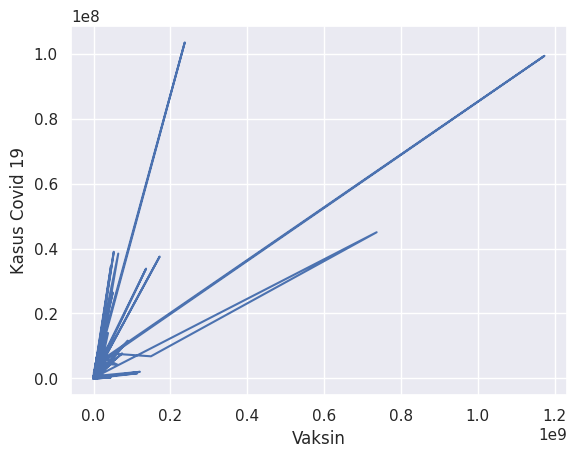

In [ ]:
## melihat Pengaruh Vaksin terhadap kasus Covid-19
plt.plot(df_vak_cov.Mean_Person_Vac, df_vak_cov.New_cases)
plt.xlabel('Vaksin')
plt.ylabel('Kasus Covid 19');

Dari sini terlihat adanya pengaruh antara vaksin terhadap kasus dan kematian Covid-19 di tiap negara. Semakin tinggi tingkat vaksin di suatu negara maka semakin sedikit kasus dan kematian di suatu negara.

## 4. Tingkat keefektifan vaksin berdasarkan rata-rata dosis pada kasus COVID-19 di tiap wilayah WHO

<Axes: title={'center': 'Hubungan Tingkat keefektifan vaksin berdasarkan rata-rata dosis pada kasus COVID-19 '}, xlabel='New_cases', ylabel='Mean_dosis_vaksin'>

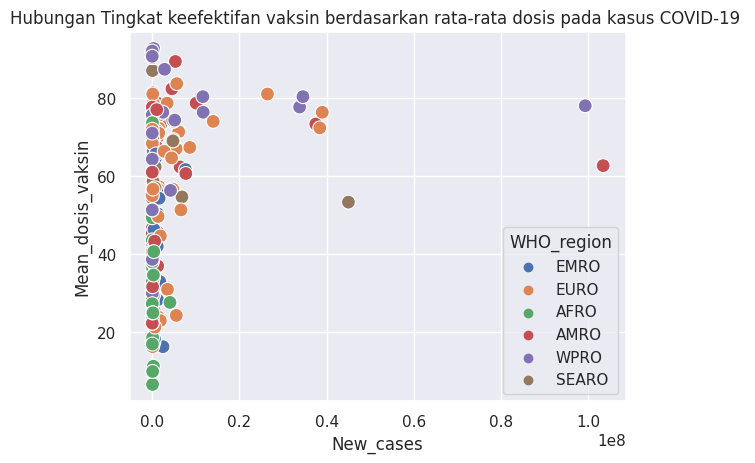

In [ ]:
#Memvisualisasikan pengaruh tingkat dosis vaksin terhadap kasus Covid 19
plt.title('Hubungan Tingkat keefektifan vaksin berdasarkan rata-rata dosis pada kasus COVID-19 ')
sns.scatterplot(x='New_cases',
                y='Mean_dosis_vaksin',
                hue='WHO_region',
                s=100,
                data=df_vak_cov)

<Axes: title={'center': 'Hubungan Tingkat keefektifan vaksin berdasarkan rata-rata dosis pada tingkat kematian '}, xlabel='Tingkat_Kematian', ylabel='Mean_dosis_vaksin'>

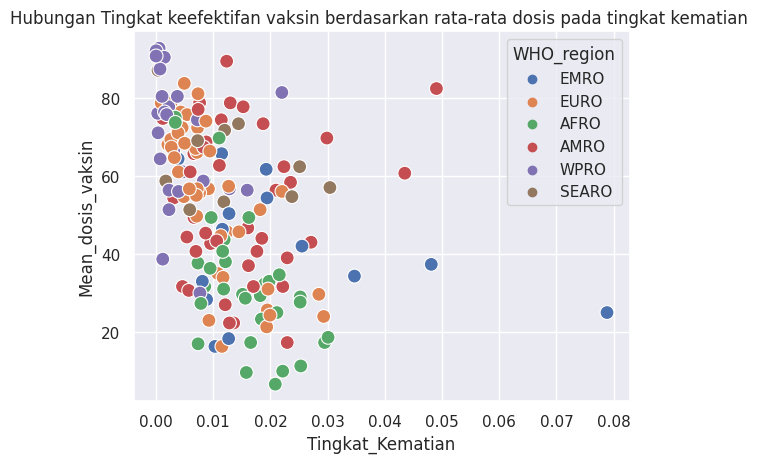

In [ ]:
#Memvisualisasikan pengaruh tingkat dosis vaksin terhadap tingkat kematian Covid 19
plt.title('Hubungan Tingkat keefektifan vaksin berdasarkan rata-rata dosis pada tingkat kematian ')
sns.scatterplot(x='Tingkat_Kematian',
                y='Mean_dosis_vaksin',
                hue='WHO_region',
                s=100,
                data=df_vak_cov)

Dari sini terlihat adanya pengaruh antara tingkat keefektifan vaksin berdasarkan rata-rata dosis pada kasus COVID-19 di tiap wilayah WHO. Semakin tinggi rata-rata dosis vaksin di suatu negara maka semakin sedikit kkematian di setiap wilayah WHO.

## 5. Melihat efek perbandingan tingkat vaksin dan tingkat dosis vaksin terhadap tingkat kematian covid di setiap benua

array([<Axes: title={'center': 'means_vac'}, xlabel='WHO_region'>,
       <Axes: title={'center': 'means_dosis'}, xlabel='WHO_region'>],
      dtype=object)

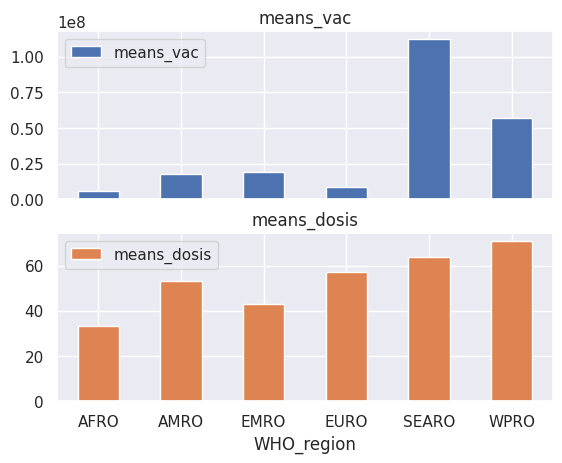

In [ ]:
### Membandingkan rata-rata tingkat vaksin dan rata-rata tingkat dosis vaksin
dosis_vac_benua.plot.bar(rot=0, subplots=True)

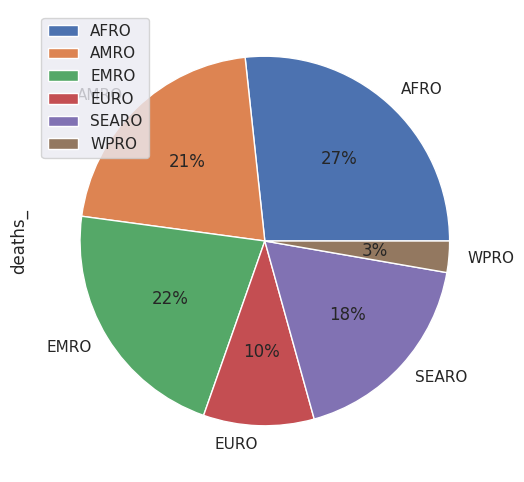

In [ ]:
### Membandingkan tingkat kematian Covid 19 di setiap benua menggunakan pie chart
plot = df_region_kematian.plot.pie(subplots=True, figsize=(11, 6), autopct='%1.0f%%')

Dari sini kita lihat bahwa penanganan Covid-19 dengan melakukan vaksin dan dosis vaksin mempunyai pengaruh terhadap tingkat kematian di setiap WHO region. Seperti pada daerah WPRO yang memiliki tingkat vaksin dan dosis vaksin perorang yang cendurung tinggi ternyata menghasilkan tingkat kematian yang paling rendah dibanding region WHO lain. Sedangkan daerah AFRO yang yang memiliki tingkat vaksin dan dosis vaksin perorang yang cendurung rendah, ternyata menghasilkan tingkat kematian yang paling tinggi dibanding region WHO lain.

# **5. PENUTUPAN**

## Kesimpulan

Dari analisis yang telah dilakukan, dapat diperoleh kesimpulan bahwa

1. kasus covid-19 dari tahun 2021 awal sampai tahun 2022 akhir, semakin banyak kasus baru, dan puncaknya pada 2023 Januari. Setelah itu kasus mulai menurun. Berdasarkan data  terlihat bahwa kasus terbaru banyak terjadi pada hari Minggu. Ini terjadi karena  peningkatan mobilitas dan kontak sosial.

2. Vaksinasi mempengaruhi tingkat kematian, bagi yang tidak melakukan vaksinasi mempunyai tinggkat kematian yang lebih tinggi. Dari data diketahui efek vaksin berdasarkan rata rata dosis di tiap wilayah akan memperkecil kasus baru covid-19 dan tingkat kematian akan lebih rendah. Kemudia dari data dapat dilihat benua Afrika mempunya tingkat kematian lebih tinggi dibanding benua lain.

## LINK

- ## Sumber Data:
https://data.who.int/dashboards/covid19/data?n=c
- ## Jupyter Notebook -> Code & penjelasan~Interpretasi:
https://colab.research.google.com/drive/1QjypuyemAwN-N6fZegFkYpx8H8z76oa0?usp=sharing
- ## File data hasil preprocessing:
1. Data covid : https://drive.google.com/file/d/1lZhfJbQtxnOPtSbruLWLh7aC-pg6xi7D/view?usp=sharing
2. Data Vaksin: https://drive.google.com/file/d/1AWfeZ4WO8Rj0imN0o_fgzibgDgRqnM6w/view?usp=sharing
- ## File salindia:
https://docs.google.com/presentation/d/173e2cHWJVeiiMxhWxLzbqke8947-6Dd6/edit?usp=sharing&ouid=105137570457853937918&rtpof=true&sd=true
- ## Link video presentasi:
https://youtu.be/NNYgBBqcN_8